[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/vzavala/PIML_PEQ_2026/blob/main/JupyterNotebooks/PCML_Module2_UDE_CSTR.ipynb)

# Module 2 Tutorial: Dynamic Hybrids (UDEs) and Physics-Informed Filtering for a CSTR
## Physics-Constrained Machine Learning: Concepts, Tools, and Algorithms

**Victor M. Zavala and Angan Mukherjee — University of Wisconsin-Madison**

ML models are flexible, but with **limited data** they overfit and generalize poorly. In this tutorial we use the CSTR
of Module 1 to show how physical knowledge helps. We will:

1. Build a **dynamic hybrid** (universal differential equation, UDE) that embeds the structure of the balances and learns
   from a single experiment with a tiny NN; we compare it with the neural ODE of Module 1.
2. Use an approximate physics model to **filter** the experimental domain before collecting data.

### Connection to the slides (Module 2)

The UDE is a physics-constrained (composite) model for dynamic systems; filtering uses physics to narrow down the
training space. The other paradigms (additive, PINN, PCNN) are illustrated in the membrane tutorial.

### Before the workshop

    conda create -n pcml -c conda-forge python=3.11 numpy scipy matplotlib scikit-learn jupyterlab ipykernel
    conda activate pcml
    python -m pip install torch
    jupyter lab

On Google Colab, all required packages are already installed. The whole notebook runs in a few minutes on a laptop.

In [1]:
import time
import warnings
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp
import torch
from torch import nn
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel, RBF

warnings.filterwarnings("ignore")
SEED = 26
rng = np.random.default_rng(SEED)
torch.set_default_dtype(torch.float64)

plt.rcParams.update({
    "text.usetex": False, # Set to True if you have an external LaTeX installation
    "font.family": "serif",
    "axes.labelsize": 14,
    "axes.titlesize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
    "legend.fontsize": 10,
})

### 1. The CSTR and the physical knowledge available

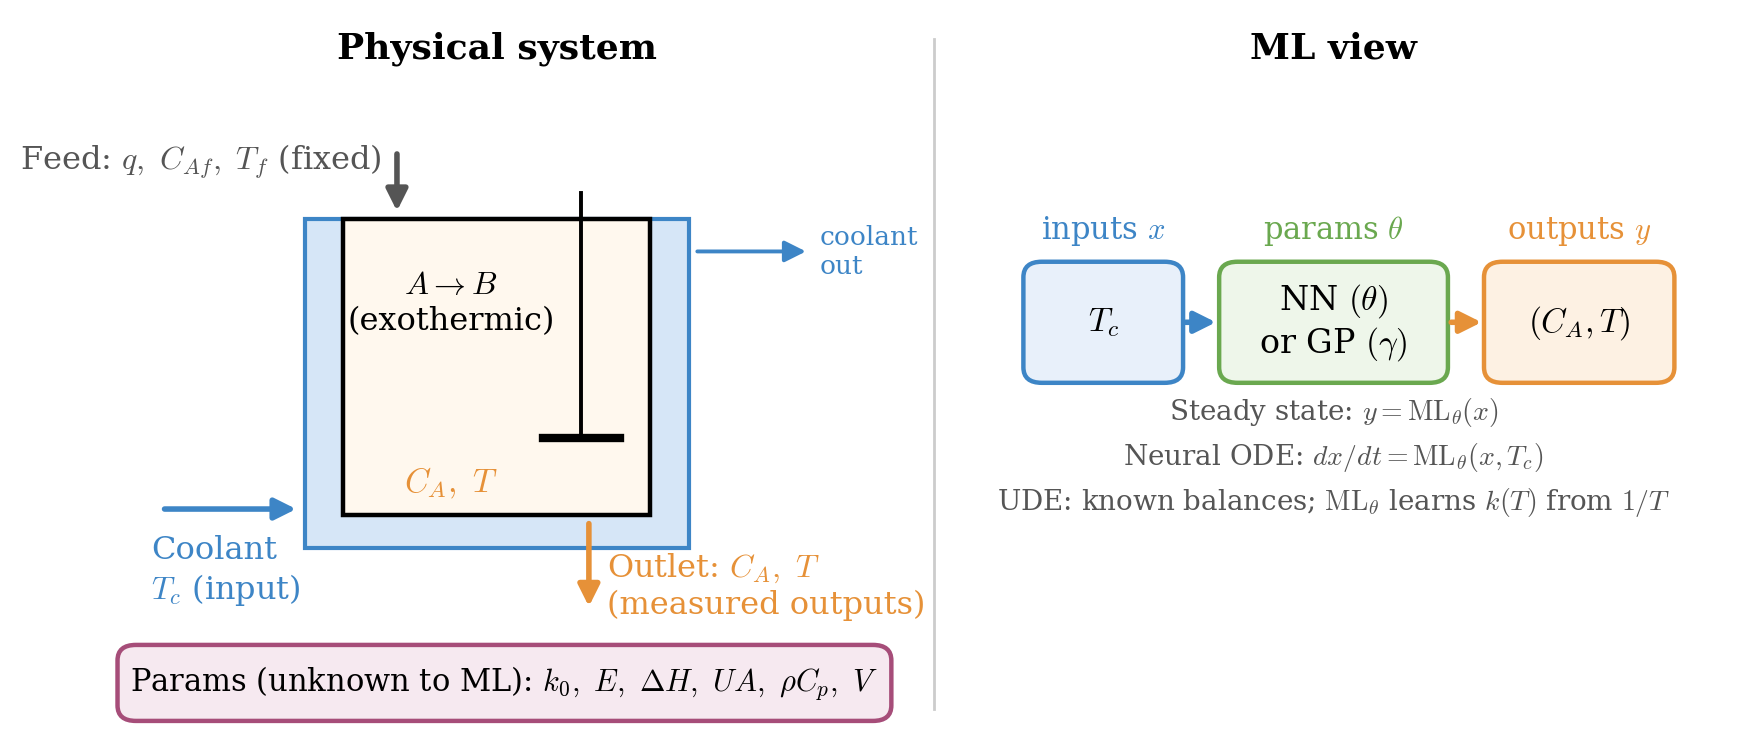

We use the same CSTR as in Module 1 (states $C_A$, $T$; input $T_c$):

$$\frac{dC_A}{dt}=\frac{q}{V}(C_{Af}-C_A)-r,\qquad
\frac{dT}{dt}=\frac{q}{V}(T_f-T)+\frac{(-\Delta H)}{\rho C_p}\,r+\frac{UA}{V\rho C_p}(T_c-T),\qquad r=k_0e^{-E/RT}C_A$$

The true model is used **only to generate data**. We assume that we know some of the physics:

**(i) Structure of the dynamic balances.** We know the flow, heat-of-reaction, and cooling terms of the ODEs, and we know
that the rate is proportional to the concentration, $r=k(T)\,C_A$; only the rate constant $k(T)$ is unknown (Section 3).

**(ii) Approximate model (uncertain kinetics).** We know the full model, but our estimate of the pre-exponential factor
is 20% too low ($0.8\,k_0$). This model captures the coarse behavior of the reactor (Section 4).

In [2]:
q, V = 100.0, 100.0          # L/min, L
CAf, Tf = 1.0, 350.0         # mol/L, K
rho, Cp = 1000.0, 0.239      # g/L, J/(g K)
dH = -5.0e4                  # J/mol
ER, k0 = 8750.0, 7.2e10      # K, 1/min
UA = 5.0e4                   # J/(min K)

a, b, c = q/V, -dH/(rho*Cp), UA/(V*rho*Cp)


def cstr_rhs(t, x, Tc, k=k0):
    r = k*np.exp(-ER/x[1])*x[0]
    return [a*(CAf - x[0]) - r, a*(Tf - x[1]) + b*r + c*(Tc - x[1])]


def steady_state(Tc, k=k0):
    sol = solve_ivp(cstr_rhs, [0, 300.0], [0.9, 310.0], args=(Tc, k), method="LSODA", rtol=1e-8, atol=1e-10)
    return sol.y[:, -1]


def physics_approx(Tc_values):
    # approximate model: kinetics with 0.8*k0
    return np.array([steady_state(Tc, 0.8*k0) for Tc in Tc_values])


def balance(CA, T, Tc):
    # residual of the exact balance g(CA,T,Tc), scaled to units of K
    return (a*(Tf - T) + c*(Tc - T) + b*a*(CAf - CA))/(a + c)


labels = [r"$C_A$ (mol/L)", r"$T$ (K)"]

### 2. Common settings

We use the same measurement noise as in Module 1, $\sigma=(0.005\ \mathrm{mol/L},\ 0.5\ \mathrm{K})$, and a GP helper for Section 4.

In [3]:
sigma = np.array([0.005, 0.5])


def fit_gp(x, y, j):
    kernel = ConstantKernel(1.0, (1e-3, 1e3))*RBF(1.0, (1e-2, 1e2))
    gp = GaussianProcessRegressor(kernel=kernel, alpha=(sigma[j]/y.std())**2, normalize_y=True,
                                  n_restarts_optimizer=10, random_state=SEED)
    return gp.fit(x, y)

### 3. Dynamic hybrid: universal differential equation (UDE)

In Module 1, the neural ODE learned the **entire** right-hand side of the ODEs from data. Here we embed the known
structure of the balances (flow, heat-of-reaction, and cooling terms) and use a NN **only for the unknown rate constant**:

$$\frac{dC_A}{dt}=\frac{q}{V}(C_{Af}-C_A)-r,\qquad
\frac{dT}{dt}=\frac{q}{V}(T_f-T)+\frac{(-\Delta H)}{\rho C_p}\,r+\frac{UA}{V\rho C_p}(T_c-T),\qquad
r=C_A\,k_{ref}\exp\left({\color{blue}\mathrm{ML}_\theta(1/T)}\right)$$

This is a composite structure $y=\mathrm{PH}(x,{\color{blue}\mathrm{ML}_\theta(x)})$ known as a **universal differential equation** (ML component in blue).
The system input is still $T_c$; inside the model, the NN takes $1/T$ (a physics-based feature of the state $T$), has 2 tanh neurons, and one output: **7 parameters**, compared with
98 parameters for the neural ODE of Module 1.

Both models are trained the same way (repeated simulation and fitting of trajectories), using **a single experiment**
($T_c$ stepped from 290 to 300 K). We then predict the response to five other coolant temperatures. For reference,
we also train the neural ODE with three experiments ($T_c$ = 286, 294, and 300 K), as in Module 1.

In [4]:
x0 = steady_state(290.0)
dt = 0.2
t_sim = np.arange(0.0, 8.0 + dt/2, dt)
obs_idx = np.arange(2, len(t_sim), 2)          # measurement every 0.4 min
t_obs = t_sim[obs_idx]


def simulate(Tc, t_eval):
    sol = solve_ivp(cstr_rhs, [0, t_eval[-1]], x0, args=(Tc,), t_eval=t_eval, method="LSODA", rtol=1e-8, atol=1e-10)
    return sol.y.T


Tc_exps = [286.0, 294.0, 300.0]
rng_dyn = np.random.default_rng(SEED)
Y_exps = {Tc: simulate(Tc, t_sim)[obs_idx] + rng_dyn.normal(size=(len(t_obs), 2))*sigma for Tc in Tc_exps}


class NeuralODE(nn.Module):
    # Module 1: NN models the whole vector field (98 parameters)
    def __init__(self, n_hidden=16):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(3, n_hidden), nn.Tanh(), nn.Linear(n_hidden, 2))
        with torch.no_grad():
            self.net[2].weight.mul_(0.1)
            self.net[2].bias.zero_()

    def forward(self, x, Tc):
        z = torch.cat([(x[:, :1] - 0.93)/0.05, (x[:, 1:] - 320.0)/10.0, (Tc - 293.5)/8.5], dim=1)
        f = self.net(z)
        return torch.cat([0.05*f[:, :1], 10.0*f[:, 1:]], dim=1)


class UDE(nn.Module):
    # known balance structure; NN only learns the rate constant k(T) (7 parameters)
    def __init__(self, n_hidden=2):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, n_hidden), nn.Tanh(), nn.Linear(n_hidden, 1))

    def forward(self, x, Tc):
        CA, T = x[:, :1], x[:, 1:]
        z = (1000.0/T - 3.125)/0.1                    # physics-based feature: 1/T (scaled)
        r = CA*0.05*torch.exp(self.net(z))            # r = k(T)*CA
        dCA = a*(CAf - CA) - r                        # known mass balance structure
        dT = a*(Tf - T) + b*r + c*(Tc - T)            # known energy balance structure
        return torch.cat([dCA, dT], dim=1)


def rk4(model, Tc_values, n_steps):
    # simulate the model from x0 for a batch of coolant temperatures
    x = torch.tensor(np.tile(x0, (len(Tc_values), 1)))
    Tc = torch.tensor(np.asarray(Tc_values)[:, None])
    path = [x]
    for _ in range(n_steps):
        k1 = model(x, Tc)
        k2 = model(x + dt*k1/2, Tc)
        k3 = model(x + dt*k2/2, Tc)
        k4 = model(x + dt*k3, Tc)
        x = x + dt*(k1 + 2*k2 + 2*k3 + k4)/6
        path.append(x)
    return torch.stack(path, dim=1)


def train_dynamic(model, Tc_train_dyn, iters=1500):
    # repeated simulation and fitting of simulated trajectories to measured ones
    optimizer = torch.optim.Adam(model.parameters(), lr=0.01)
    Y, sig = torch.tensor(np.array([Y_exps[Tc] for Tc in Tc_train_dyn])), torch.tensor(sigma)
    t0 = time.perf_counter()
    for it in range(iters):
        optimizer.zero_grad()
        X_hat = rk4(model, Tc_train_dyn, len(t_sim) - 1)
        loss = 0.5*torch.mean(torch.sum(((X_hat[:, obs_idx] - Y)/sig)**2, dim=2))
        loss.backward()
        optimizer.step()
    n_par = sum(p.numel() for p in model.parameters())
    print(f"{type(model).__name__}: {n_par} parameters, final loss {loss.item():.2f}, "
          f"training time {time.perf_counter() - t0:.0f} s")
    return model


torch.manual_seed(SEED)
node = train_dynamic(NeuralODE(), [300.0])           # one experiment
torch.manual_seed(SEED)
ude = train_dynamic(UDE(), [300.0])                  # one experiment
torch.manual_seed(SEED)
node3 = train_dynamic(NeuralODE(), Tc_exps)          # three experiments

NeuralODE: 98 parameters, final loss 0.65, training time 23 s


UDE: 7 parameters, final loss 0.65, training time 27 s


NeuralODE: 98 parameters, final loss 1.11, training time 23 s


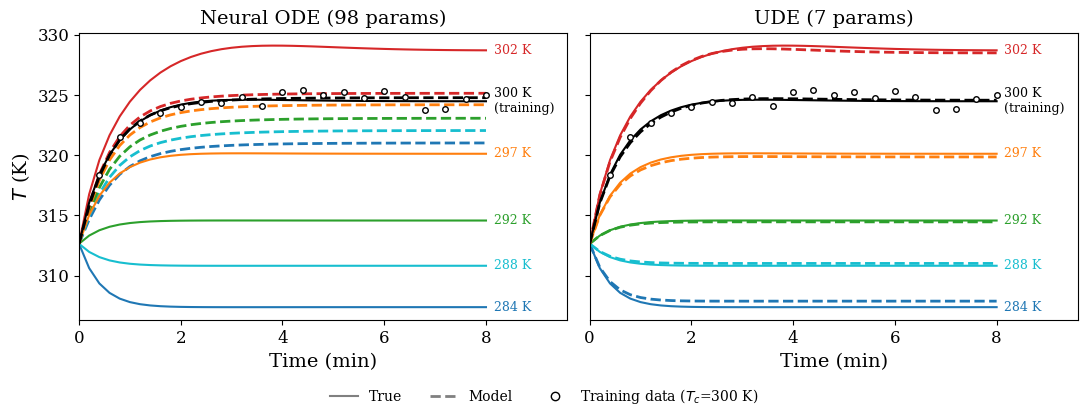

Average RMSE over the five test conditions
Neural ODE (1 experiment)  : CA = 0.0316 mol/L, T = 7.61 K
Neural ODE (3 experiments) : CA = 0.0075 mol/L, T = 0.46 K
UDE (1 experiment)         : CA = 0.0033 mol/L, T = 0.24 K


In [5]:
Tc_test = [284.0, 288.0, 292.0, 297.0, 302.0]
X_true = np.array([simulate(Tc, t_sim) for Tc in Tc_test])
with torch.no_grad():
    X_node = rk4(node, Tc_test, len(t_sim) - 1).numpy()
    X_ude = rk4(ude, Tc_test, len(t_sim) - 1).numpy()
    X_node3 = rk4(node3, Tc_test, len(t_sim) - 1).numpy()

# training condition (Tc = 300 K): true trajectory and model fits
X_true_train = simulate(300.0, t_sim)
with torch.no_grad():
    fit = {"Neural ODE (98 params)": rk4(node, [300.0], len(t_sim) - 1)[0].numpy(),
           "UDE (7 params)": rk4(ude, [300.0], len(t_sim) - 1)[0].numpy()}

fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
colors = ["tab:blue", "tab:cyan", "tab:green", "tab:orange", "tab:red"]
for ax, (lab, X) in zip(axes, [("Neural ODE (98 params)", X_node), ("UDE (7 params)", X_ude)]):
    # test conditions (not seen in training): solid = true, dashed = model
    for k, Tc in enumerate(Tc_test):
        ax.plot(t_sim, X_true[k, :, 1], "-", color=colors[k], lw=1.5)
        ax.plot(t_sim, X[k, :, 1], "--", color=colors[k], lw=2)
        ax.text(8.15, X_true[k, -1, 1], fr"{Tc:.0f} K", color=colors[k], fontsize=9, va="center")
    # training condition: data (circles), true (solid black), and model fit (dashed black)
    ax.plot(t_sim, X_true_train[:, 1], "k-", lw=1.5)
    ax.plot(t_sim, fit[lab][:, 1], "k--", lw=2)
    ax.plot(t_obs, Y_exps[300.0][:, 1], "ko", mfc="w", ms=4)
    ax.text(8.15, X_true_train[-1, 1], "300 K\n(training)", fontsize=9, va="center")
    ax.set(xlabel="Time (min)", title=lab, xlim=(0, 9.6))
axes[0].set_ylabel(labels[1])
handles = [plt.Line2D([], [], color="gray", ls="-", lw=1.5, label="True"),
           plt.Line2D([], [], color="gray", ls="--", lw=2, label="Model"),
           plt.Line2D([], [], color="k", marker="o", mfc="w", ls="none", label="Training data ($T_c$=300 K)")]
fig.legend(handles=handles, loc="lower center", ncol=3, fontsize=10, frameon=False)
plt.tight_layout(rect=(0, 0.07, 1, 1))
plt.show()

print("Average RMSE over the five test conditions")
for lab, X in [("Neural ODE (1 experiment)", X_node), ("Neural ODE (3 experiments)", X_node3), ("UDE (1 experiment)", X_ude)]:
    e = np.sqrt(np.mean((X - X_true)**2, axis=1)).mean(axis=0)
    print(f"{lab:27s}: CA = {e[0]:.4f} mol/L, T = {e[1]:.2f} K")

**Observations**

- Both models fit the single training experiment (black) equally well. The flexible neural ODE, however, overfits this experiment:
  it does not know how the dynamics depend on $T_c$ and cannot generalize to other coolant temperatures.
- The UDE knows the structure of the balances; with a single experiment and a tiny NN (7 parameters), it predicts the
  response to new coolant temperatures accurately (colored lines; solid: true, dashed: model).
- The UDE trained with one experiment is more accurate than the neural ODE trained with three experiments.
- Physics **regularizes** the model: it restricts what the NN must learn, so the model generalizes from limited data.
- **Physics reduces the complexity of the NN that is needed** and **the amount of data needed**.

### 4. Physics-informed filtering of the experimental domain

Suppose that we can run experiments for $T_c\in[280,310]$ K, but for safety the reactor temperature must stay below
$T_{max}=335$ K (above about 304 K the true reactor ignites). Before running any experiment, we use the **approximate
physics** to predict the temperature, and we keep only coolant temperatures with predicted $T\le 325$ K (a 10 K safety
margin). This gives a filtered domain $X'\subset X$: physics **narrows down** the space in which we collect data.

We compare 10 random experiments in $X$ against 10 random experiments in $X'$, and we train a GP for the temperature
with each data set. We evaluate the GP on the safe region $T_c\in[280,303]$ K.

Filtered domain X' = [280, 302.5] K


X  : average unsafe experiments = 2.65 of 10, median RMSE of T in safe region = 4.94 K
X' : average unsafe experiments = 0.00 of 10, median RMSE of T in safe region = 0.76 K


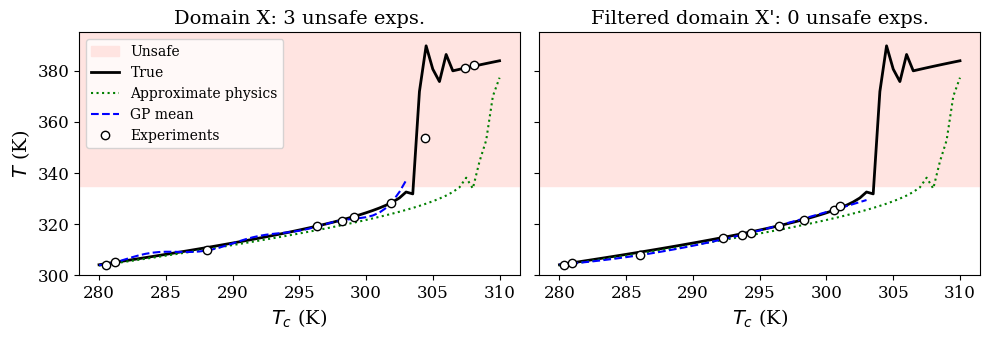

In [6]:
T_max, margin = 335.0, 10.0
Tc_cand = np.arange(280.0, 310.01, 0.5)
T_ph_cand = physics_approx(Tc_cand)[:, 1]
Tc_filter_hi = Tc_cand[T_ph_cand <= T_max - margin].max()
print(f"Filtered domain X' = [280, {Tc_filter_hi}] K")

Tc_safe = np.linspace(280.0, 303.0, 47)
T_safe = np.array([steady_state(Tc) for Tc in Tc_safe])[:, 1]


def run_design(hi, seed):
    r = np.random.default_rng(seed)
    Tc = np.sort(r.uniform(280.0, hi, 10))
    T = np.array([steady_state(t) for t in Tc])[:, 1] + r.normal(size=10)*sigma[1]
    gp = fit_gp(((Tc - 295)/10)[:, None], T, 1)
    mu = gp.predict(((Tc_safe - 295)/10)[:, None])
    return Tc, T, mu, (T > T_max).sum(), np.sqrt(np.mean((mu - T_safe)**2))


stats_filter = {"X": [], "X'": []}
for s in range(20):
    for key, hi in [("X", 310.0), ("X'", Tc_filter_hi)]:
        _, _, _, n_unsafe, err = run_design(hi, seed=s)
        stats_filter[key].append((n_unsafe, err))
for key, v in stats_filter.items():
    v = np.array(v)
    print(f"{key:3s}: average unsafe experiments = {v[:, 0].mean():.2f} of 10, "
          f"median RMSE of T in safe region = {np.median(v[:, 1]):.2f} K")

# plot a typical random design (number of unsafe experiments close to the average)
n_typ = int(round(np.mean(np.array(stats_filter["X"])[:, 0])))
s_plot = int(np.argmax(np.array(stats_filter["X"])[:, 0] == n_typ))
T_true_cand = np.array([steady_state(t) for t in Tc_cand])[:, 1]
fig, axes = plt.subplots(1, 2, figsize=(10, 3.5), sharey=True)
for ax, (lab, hi) in zip(axes, [("Domain X", 310.0), ("Filtered domain X'", Tc_filter_hi)]):
    Tc, T, mu, n_unsafe, err = run_design(hi, seed=s_plot)
    ax.axhspan(T_max, 400, color="mistyrose", label="Unsafe")
    ax.plot(Tc_cand, T_true_cand, "k-", lw=2, label="True")
    ax.plot(Tc_cand, T_ph_cand, "g:", label="Approximate physics")
    ax.plot(Tc_safe, mu, "b--", label="GP mean")
    ax.plot(Tc, T, "o", mfc="w", mec="k", label="Experiments")
    ax.set(xlabel=r"$T_c$ (K)", title=f"{lab}: {n_unsafe} unsafe exps.", ylim=(300, 395))
axes[0].set_ylabel(labels[1])
axes[0].legend(loc="upper left")
plt.tight_layout()
plt.show()

**Observations**

- Without filtering, about a quarter of the experiments fall in the unsafe ignition region; these experiments are
  wasted (and dangerous) and the GP struggles to capture the jump in temperature.
- With filtering, all experiments are safe and the GP is much more accurate in the region of interest.
- The physics model is only approximate (it predicts ignition too late); the safety margin protects us against this error.
- Filtering does not change the ML model or its training; physics is used **before** training to decide where to collect data.

### 5. Key takeaways

- ML models are flexible but, with limited data, they overfit and generalize poorly.
- Physics **mitigates limited data**: the UDE learned the reactor dynamics from a single experiment, and was more accurate
  than a neural ODE trained with three experiments.
- Physics **regularizes** ML models and **reduces the complexity** of the NN that is needed (7 vs. 98 parameters).
- Physics **narrows down** the space in which we collect data and train (filtering).

### 6. Optional exercises

1. **More data for the neural ODE.** Train the neural ODE with five experiments. How close does it get to the UDE?
2. **Even less NN.** Replace the NN in the UDE by a linear function of $1/T$ (Arrhenius law). What do you observe?
3. **Wrong structure.** Remove the cooling term from the UDE. What happens to the predictions?
4. **Filtering margin.** Repeat the filtering study with margins of 0 K and 20 K.

### References

- Mukherjee, A., and Zavala, V. M. (2026). *Physics-Constrained Machine Learning for Chemical Engineering*. Current Opinion in Chemical Engineering, 51, 101228. https://doi.org/10.1016/j.coche.2026.101228
- Raissi, M., Perdikaris, P., and Karniadakis, G. E. (2019). Physics-informed neural networks. *Journal of Computational Physics*, 378, 686–707.
- Rackauckas, C., et al. (2020). Universal differential equations for scientific machine learning. arXiv:2001.04385.
- Thompson, J., Connors, B. M., Zavala, V. M., and Venturelli, O. S. (2026). Physics-constrained neural ordinary differential
  equation models to discover and predict microbial community dynamics. *PNAS*, 123(13), e2517661123.
- González, L. D., and Zavala, V. M. (2023). New paradigms for exploiting parallel experiments in Bayesian optimization.
  *Computers & Chemical Engineering*, 170, 108110.